In [2]:
%run notebook_setup.py

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.utils.config import load_config

In [3]:
config = load_config()

In [4]:
raw_data_path = config["paths"]["raw_data"]

df = pd.read_csv(raw_data_path)

In [5]:
df.head()

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909


In [7]:
df["Area"].value_counts()

Area
1.0         113
3.0          75
2.0          66
4.0          49
5.0          42
           ... 
4571.0        1
39560.0       1
310883.0      1
275746.0      1
239344.0      1
Name: count, Length: 13644, dtype: int64

### In Preprocessing
 - Convert 'Area' feature from 'float' into 'int'
 - Remove Outliers from Dataset. 'All numerical feature except Crop_Year'
 - Split into train and test dataset
 - OneHotEncoding on Season and State
 - Frequency Encoding on Crop "High Cardinality".
 - StandardScaler on numerical features.

In [8]:
df["Area"] = df["Area"].astype(int)

In [9]:
df["Area"].dtypes

dtype('int64')

In [11]:
# Remove outliers
from feature_engine.outliers import ArbitraryOutlierCapper

In [15]:
def IQR_boundries(df, feature):
    q1 = df[feature].quantile(0.25)
    q3 = df[feature].quantile(0.75)

    IQR = q3 - q1
    lower_bound = q1 - 1.5 * IQR
    upper_bound = q3 + 1.5 * IQR

    return lower_bound, upper_bound

In [16]:
df.head()

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739,794,2051.4,165500.63,539.09,0.420909


In [17]:
lower_bound_production, upper_bound_production = IQR_boundries(df, "Production")

In [54]:
lower_bound_production, upper_bound_production

(np.float64(-180594.5), np.float64(304705.5))

In [20]:
num_features = df.select_dtypes(include=["number"]).columns.tolist()
cat_features = df.select_dtypes(exclude=["number"]).columns.tolist()

In [22]:
num_features.remove("Yield")

In [23]:
num_features

['Crop_Year',
 'Area',
 'Production',
 'Annual_Rainfall',
 'Fertilizer',
 'Pesticide']

In [59]:
def remove_outlier(df, numerical_features: list):
    lower_bound_dict = {}
    upper_bound_dict = {}
    for feature in numerical_features:
        lower_bound_, upper_bound_ = IQR_boundries(df, feature)
        lower_bound_dict[feature] = lower_bound_
        upper_bound_dict[feature] = upper_bound_
    
    # print(f"Lower Bound dict: {lower_bound_dict}")
    # print(f"Upper Bound dict: {upper_bound_dict}")

    capper = ArbitraryOutlierCapper(
        min_capping_dict=lower_bound_dict,
        max_capping_dict=upper_bound_dict
    )

    df_without_outliers = capper.fit_transform(df)

    return df_without_outliers


In [61]:
df_without_outliers = remove_outlier(df, num_features)

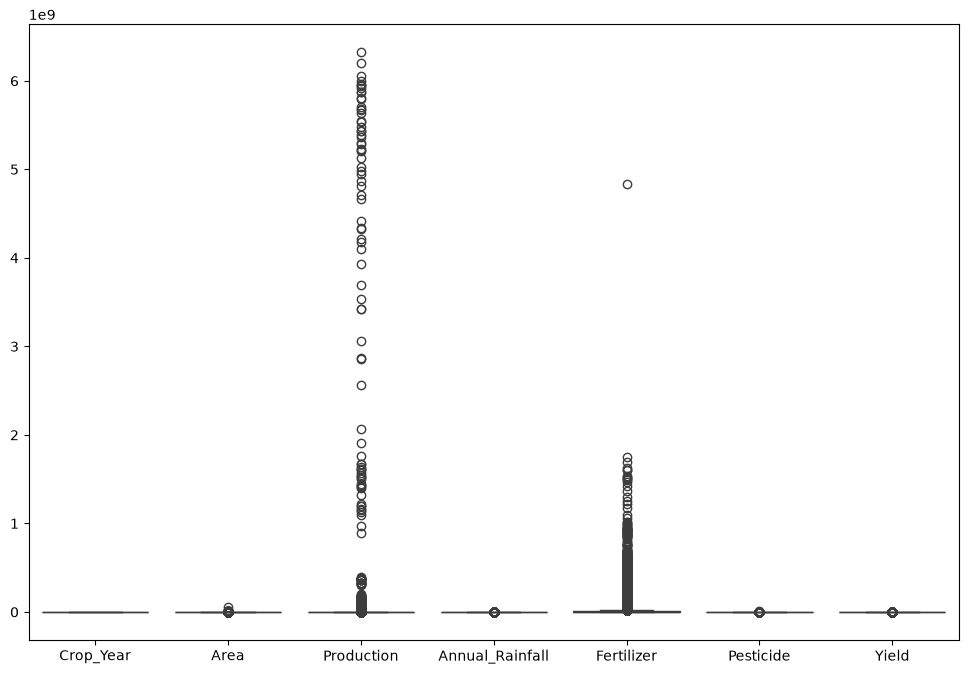

In [62]:
plt.figure(figsize=(12, 8))
sns.boxplot(df)
plt.show()

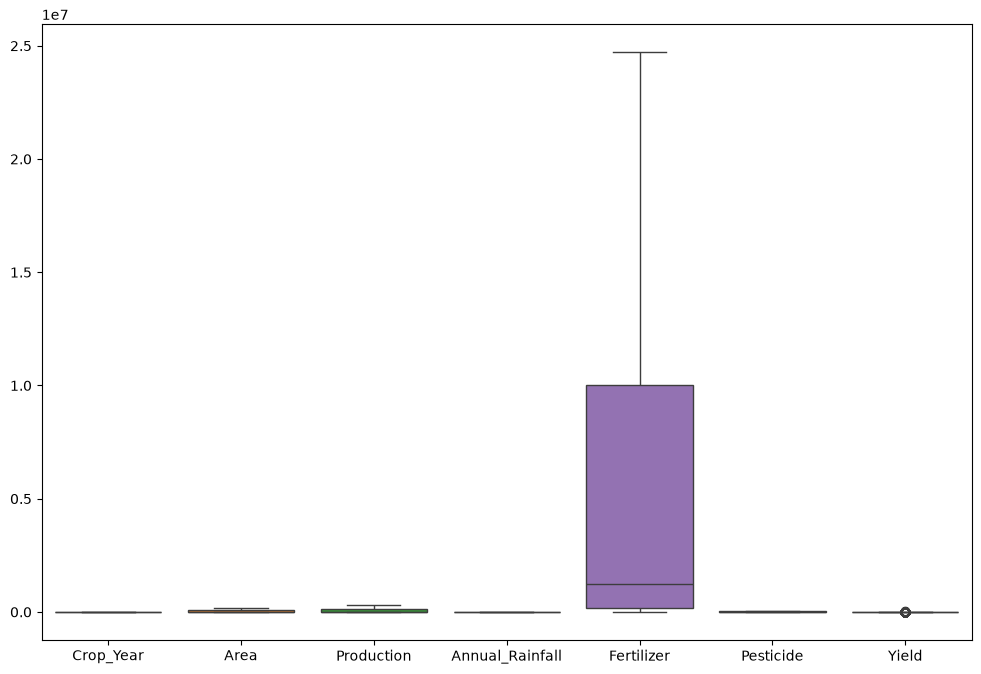

In [63]:
plt.figure(figsize=(12, 8))
sns.boxplot(df_without_outliers)
plt.show()

In [65]:
# Split into train and test dataset
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df.drop(columns=["Yield"]), 
                                                    df["Yield"], 
                                                    test_size=config["data"]["test_size"], 
                                                    random_state=42)

In [67]:
X_train.shape, X_test.shape

((15751, 9), (3938, 9))

In [79]:
y_train

19466    2.860000
17802    2.610000
7014     0.447273
14078    1.170769
8121     0.535789
           ...   
11284    2.130000
11964    3.234545
5390     9.684074
860      0.704000
15795    0.292222
Name: Yield, Length: 15751, dtype: float64

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoding, 

In [73]:
df["Crop"].value_counts()

Crop
Rice                     1197
Maize                     975
Moong(Green Gram)         740
Urad                      733
Groundnut                 725
Sesamum                   685
Potato                    628
Sugarcane                 605
Wheat                     545
Rapeseed &Mustard         528
Bajra                     524
Jowar                     513
Arhar/Tur                 508
Ragi                      498
Gram                      490
Small millets             485
Cotton(lint)              476
Onion                     454
Sunflower                 441
Dry chillies              419
Other Kharif pulses       382
Horse-gram                371
Peas & beans (Pulses)     369
Tobacco                   364
Other  Rabi pulses        355
Soyabean                  349
Turmeric                  337
Masoor                    324
Ginger                    323
Linseed                   308
Castor seed               300
Barley                    297
Sweet potato              273
Garli

In [74]:
threshold = 0.01 * len(df)
threshold

196.89000000000001

In [75]:
from category_encoders import TargetEncoder

In [77]:
encoder = TargetEncoder(
    cols=["Crop"],
    smoothing=10,
    min_samples_leaf = 20
)

In [82]:
y_train

19466    2.860000
17802    2.610000
7014     0.447273
14078    1.170769
8121     0.535789
           ...   
11284    2.130000
11964    3.234545
5390     9.684074
860      0.704000
15795    0.292222
Name: Yield, Length: 15751, dtype: float64

In [83]:
X_train["Crop_Encoded"] = encoder.fit_transform(X_train["Crop"], y_train)
X_test["Crop_Encoded"] = encoder.transform(X_test["Crop"])

In [ ]:
X_train_ = X_train.drop(columns=["Crop"])
X_test_ = X_test.drop(columns=["Crop"])

In [98]:
X_train_.shape, X_train.shape

((15751, 9), (15751, 10))

In [100]:
cat_features = X_train_.select_dtypes(exclude=["number"]).columns.tolist()

In [110]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_pipeline = Pipeline([
    ("Scaling", StandardScaler())
])

cat_pipeline = Pipeline([
    "OneHotEncoding", OneHotEncoder(handle_unknown="ignore", sparse_output=False)
])
transformer = ColumnTransformer(
    transformers=[
        ('Scaling', num_pipeline, num_features),
        ('OneHotEncoding', OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_features)
    ], remainder="passthrough"
)

In [111]:
X_train_preprocessed = transformer.fit_transform(X_train_)
X_test_preprocessed = transformer.transform(X_test_)

In [114]:
X_train_preprocessed.shape, X_test_preprocessed.shape

((15751, 43), (3938, 43))

In [115]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train_preprocessed, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](43,)","[ 5.64, -6.24,-44.6 ,..., 7.02, 98.18, 1.03]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-11.92
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,43
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(41)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](43,)","[101032.29, 215.74, 127.46,..., 7.55, 0. , 0. ]"


In [116]:
y_pred = lr.predict(X_test_preprocessed)

In [117]:
from sklearn.metrics import r2_score

print(f"R2 Score of Linear Regression: {r2_score(y_test, y_pred)}")

R2 Score of Linear Regression: 0.8019786620971011
